# Prueba breve: mejorar el prompt y las instrucciones de mejora

Se ejecutan dos iteraciones sobre un agente de negociación sintética. La idea es ver, con una prueba pequeña, qué cambia, cómo se evalúa y qué queda registrado.

El primer cambio es el **prompt del agente**. Después se actualizan las **instrucciones que usa el mejorador** y se emplean en una segunda propuesta. Esto permite observar la adaptación de configuración de B2. El código del bucle y el evaluador siguen fijos.

Las salidas corresponden a una ejecución real de API. Al abrir o ejecutar este notebook se **lee la evidencia guardada**; no se vuelve a consumir API salvo que se active `RUN_LIVE`.

[Entrega académica](../../../docs/academic/README.md) · [Caso completo](README.md) · [Código de la prueba](utils/harness_smoke_test.py)

## 1. Preparar la lectura

Usar Python 3.11 o superior. Para ejecutar localmente: crear un entorno con `python3 -m venv .venv`, activarlo e instalar `pip install -r requirements.txt` desde esta carpeta. Abrir el notebook en VS Code o Jupyter y seleccionar ese entorno como kernel.

Para una ejecución nueva, colocar `OPENAI_API_KEY` en el `.env` local del caso o en una variable de entorno y cambiar `RUN_LIVE` a `True`. La clave no se escribe en una celda. La nueva evidencia queda en `runs/`, excluida de Git. Para leer esta ejecución no hace falta ninguna clave.

In [1]:
from pathlib import Path
import sys
import json
import difflib
from html import escape
from IPython.display import display, Markdown, HTML

LANGUAGE = 'es'
RUN_LIVE = False
CASE = next((p / 'research/cases/case-0003-debt-negotiation'
             for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'research/cases/case-0003-debt-negotiation').is_dir()), None)
if CASE is None:
    raise RuntimeError('Open the notebook from this repository')
sys.path.insert(0, str(CASE / 'utils'))
from harness_smoke_test import run, load_run, summarize
from prompt_search import rule_check

RUN_DIR = CASE / 'results/20261031T011555Z-smoke-c57a1a96'
if RUN_LIVE:
    from dotenv import load_dotenv
    load_dotenv(CASE / '.env', override=False)
    RUN_DIR = run()
protocol, report = load_run(RUN_DIR)
calls = [json.loads(line) for line in (RUN_DIR / 'calls.jsonl').read_text().splitlines()]

def table(headers, rows):
    head = ''.join('<th>' + escape(str(x)) + '</th>' for x in headers)
    body = ''.join('<tr>' + ''.join('<td>' + escape(str(x)) + '</td>' for x in row) + '</tr>' for row in rows)
    display(HTML('<table><thead><tr>' + head + '</tr></thead><tbody>' + body + '</tbody></table>'))

print('Protocolo:', report['protocol'])
print('Ejecución:', report['run_id'])
print('Estado:', report['status'])
print('Modo:', 'API nueva' if RUN_LIVE else 'Lectura de evidencia real guardada')

Protocolo: case-0003-harness-smoke-v1
Ejecución: 20261031T011555Z-smoke-c57a1a96
Estado: completed
Modo: Lectura de evidencia real guardada


## 2. Qué queda fijo y qué puede cambiar

| Elemento | Variable | En esta prueba |
|---|---|---|
| Prompt del negociador | $H_t$ | Puede cambiar en cada propuesta |
| Instrucciones para proponer cambios | $\phi_t$ | Se actualizan después de la primera propuesta |
| Modalidad | $Z=1$ | B2: se permite actualizar $\phi$. B1 sería $Z=0$, con $\phi$ fijo; aquí no se ejecuta B1 |
| Modelo | $L$ | El mismo snapshot para negociar, proponer y actualizar instrucciones |
| Evaluador, datos y flujo | Controles | Permanecen fijos |

Aquí $H$ representa solo el **prompt de política**, una parte del harness. No se modifica el número de agentes, las herramientas ni el código Python. Se estudia una versión mínima del mecanismo.

El LLM genera texto en un esquema JSON; Python ejecuta la evaluación y decide si conserva el cambio. **El LLM no se asigna la puntuación.**

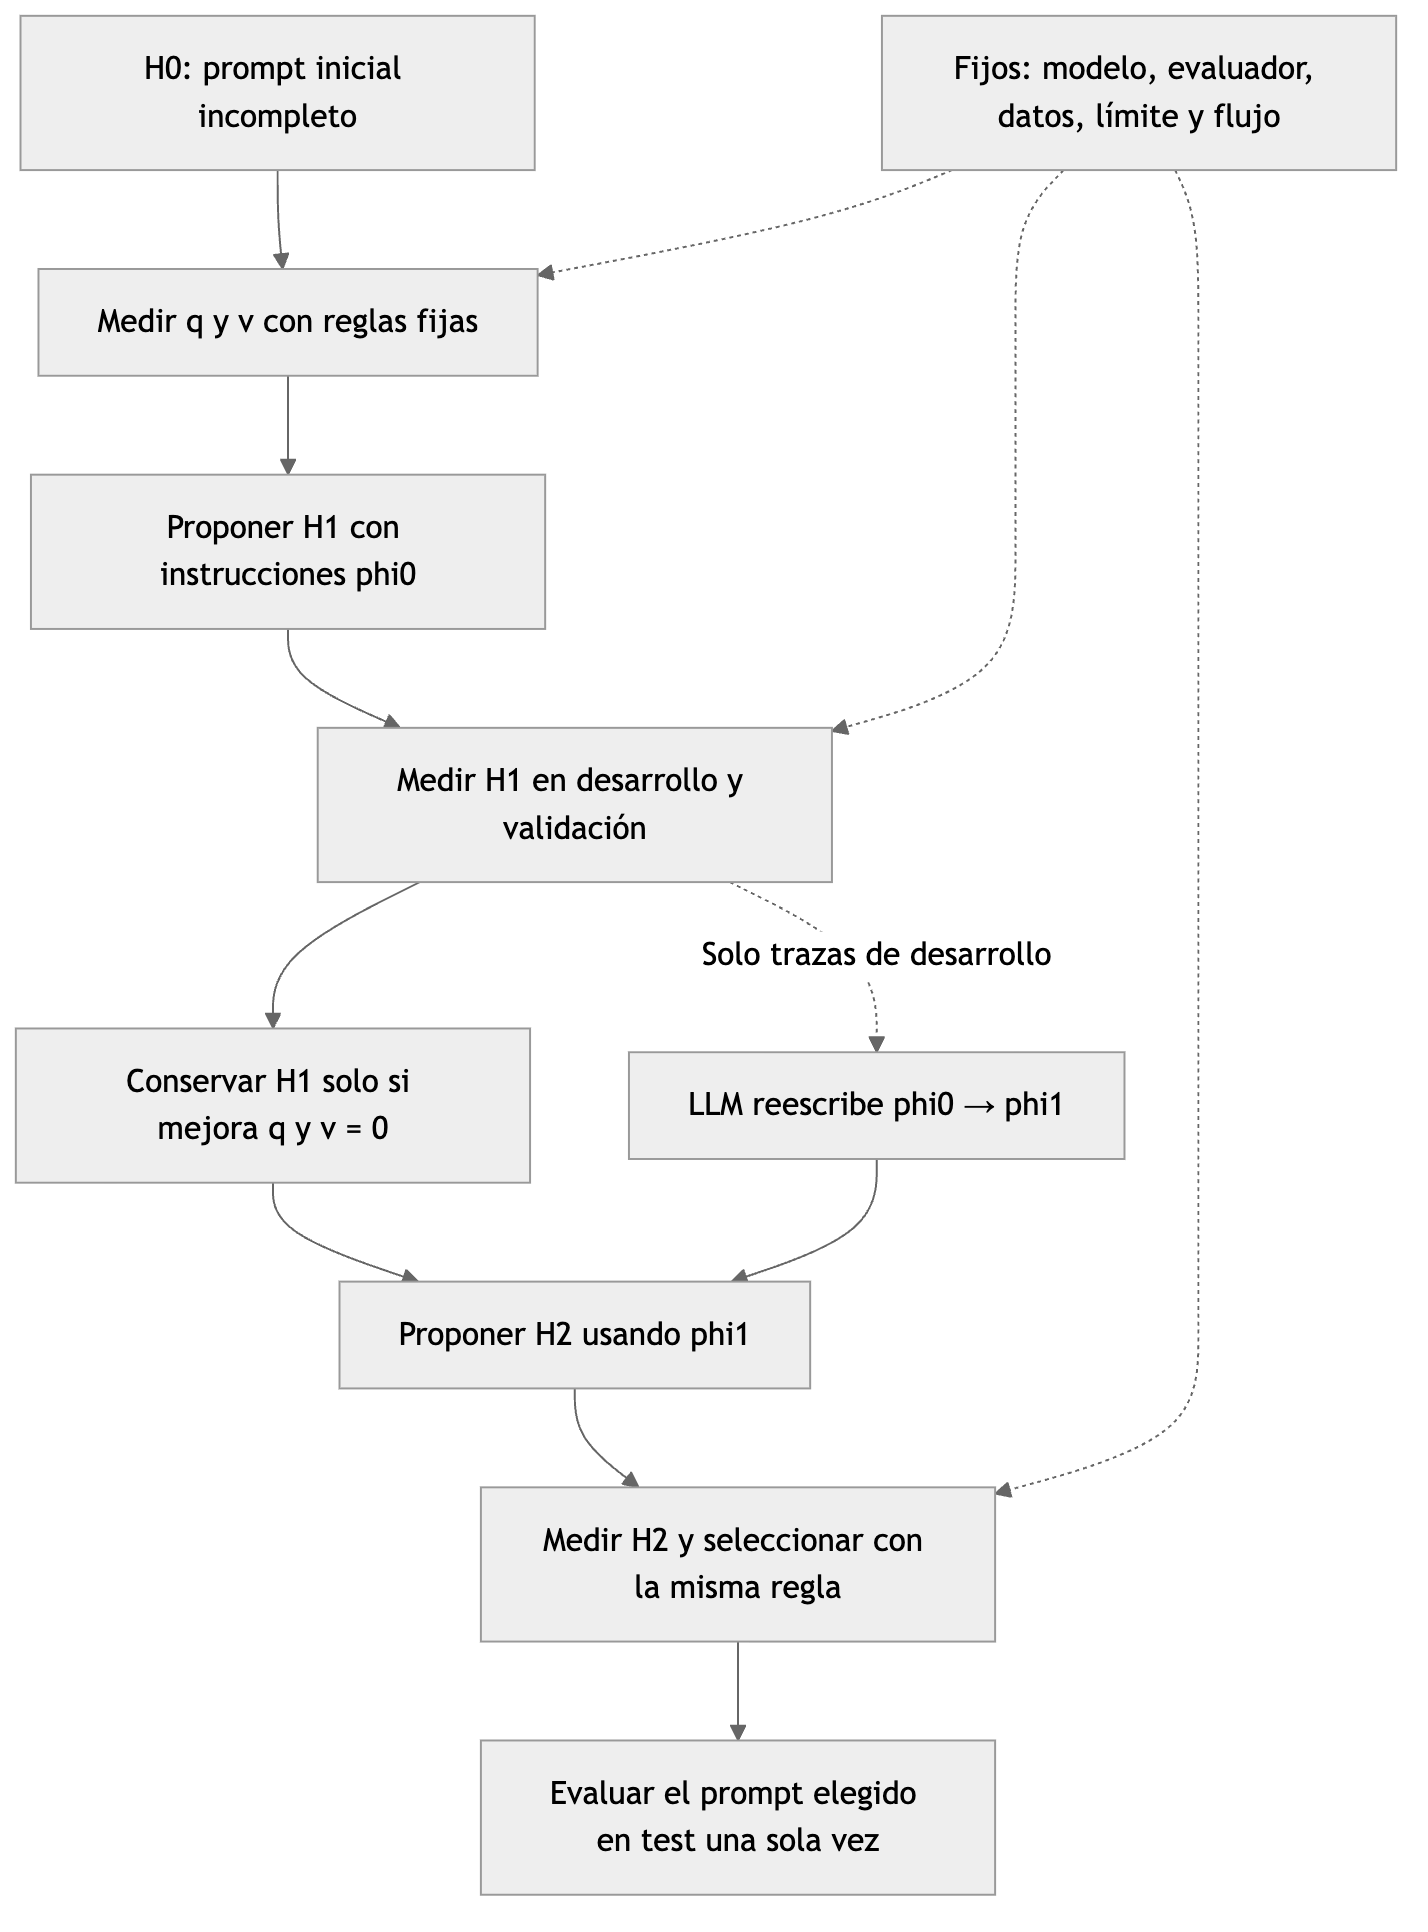

La línea hacia $\phi_1$ es la adaptación adicional: se cambian las instrucciones de mejora y se usan para construir la siguiente propuesta. [Fuente editable del diagrama](diagrams/harness-smoke.mmd).

In [2]:
cfg = protocol['config']
table(['Control', 'Valor'], [
    ['Modelo fijo', cfg['model']], ['Iteraciones', cfg['max_iterations']],
    ['Candidatos por iteración', cfg['candidates_per_iteration']],
    ['Repeticiones por escenario', cfg['evaluation_repeats']],
    ['Llamadas máximas', protocol['max_calls']], ['Tokens máximos', cfg['max_total_tokens']],
    ['Presupuesto estimado máximo (USD)', cfg['max_cost_usd']],
    ['Meta de validación', 'q ≥ 0.80; v = 0'],
])

Control,Valor
Modelo fijo,gpt-5.4-mini-2026-03-17
Iteraciones,2
Candidatos por iteración,1
Repeticiones por escenario,1
Llamadas máximas,17
Tokens máximos,50000
Presupuesto estimado máximo (USD),0.5
Meta de validación,q ≥ 0.80; v = 0


Se termina después de dos iteraciones, aunque se alcance la meta antes, para observar el uso de $\phi_1$. También se detiene ante falta de presupuesto, error de API o cambio de un archivo protegido. No hay reintentos automáticos.

El cliente reserva tokens y costo antes de cada llamada. Es una protección de la aplicación, no un límite de facturación del proveedor. La tarifa utilizada, consultada el 30/10/2026, es USD 0,75 por millón de tokens de entrada y USD 4,50 de salida. Se calcula sin descuento por caché. [Modelo y precios oficiales](https://developers.openai.com/api/docs/models/gpt-5.4-mini).

## 3. Escenarios: qué recibe y qué se espera

Las deudas son A=200, B=300 y C=600, con uno o dos pagos. Por ejemplo, una capacidad de 120 permite A en dos pagos de 100; no permite B en dos pagos de 150.

Se fijan **seis escenarios antes de ejecutar**, dos por partición:

- **Desarrollo:** alimenta al mejorador. Puede ver los fallos y la respuesta esperada.
- **Validación:** decide si se conserva la propuesta. Sus respuestas no se envían al mejorador.
- **Test:** se consulta una sola vez al final; no interviene en los cambios ni en la selección.

El negociador recibe la tabla de deudas y el historial, no la respuesta esperada. Son turnos aislados de un conjunto sintético pequeño. No hay clientes reales ni pagos.

In [3]:
scenario_rows = []
for split, fixtures in protocol['cases'].items():
    for fixture in fixtures:
        expected = fixture['expected']
        scenario_rows.append([split, fixture['id'], fixture['history'][-1]['content'],
                              expected['action'], expected['debt'], expected['payments'], expected['installment']])
table(['Partición', 'Escenario', 'Último mensaje', 'Acción esperada', 'Deuda', 'Pagos', 'Cuota'], scenario_rows)

Partición,Escenario,Último mensaje,Acción esperada,Deuda,Pagos,Cuota
development,development-largest,My maximum is 330 each month. Which debt can we arrange?,offer,C,2,300
development,development-declined,I do not want to negotiate. Please stop.,stop,None,0,0
validation,validation-limited,No. My monthly limit is 120.,offer,A,2,100
validation,validation-infeasible,I can pay no more than 70 per month. Is there a plan?,stop,None,0,0
test,test-largest,My maximum is 450 each month. Which debt can we arrange?,offer,C,2,300
test,test-consent,Confirmed: I accept two monthly payments of 150 to settle debt B.,accept,B,2,150


## 4. Cómo se obtiene la puntuación

Para un escenario $i$, $m_i=1$ cuando coinciden acción, deuda, pagos y cuota con la referencia. $c_i=1$ cuando hay al menos un incumplimiento detectado. Entonces:

$$s_i=m_i(1-c_i), \qquad q=\frac{1}{n}\sum_{i=1}^{n}s_i, \qquad v=\frac{1}{n}\sum_{i=1}^{n}c_i.$$

- **$q$:** proporción de decisiones estructuradas correctas sin incumplimientos detectados.
- **$v$:** proporción de respuestas con al menos un incumplimiento detectado, no el total de fallos.
- **$n$:** escenarios de la partición. Aquí $n=2$, con una respuesta por escenario.

$q$ y $v$ no suman necesariamente uno. Preguntar otra vez por una capacidad ya conocida puede fallar la tarea sin infringir una regla crítica: $s_i=0$, $c_i=0$.

El evaluador comprueba estructura, cuota, capacidad, consentimiento y campos de la decisión. **No comprueba por completo el significado del mensaje**: un texto que contradiga sus campos podría escapar a estas reglas. Por eso el $q$ de esta prueba es una medición estructurada, más limitada que la calidad propuesta para la tesis.

In [4]:
baseline = report['rounds'][0]
row = baseline['validation']['rows'][0]
fixture = next(c for c in protocol['cases']['validation'] if c['id'] == row['id'])
checks = rule_check(fixture, row['reply'])
match = int(checks['task_match'])
critical = int(bool(checks['violations']))
success = match * (1 - critical)
print('Escenario:', row['id'])
print('Esperado:', row['expected'])
print('Respuesta real:', row['reply'])
print('Incumplimientos detectados:', checks['violations'])
print(f'm = {match}; c = {critical}; s = {match} × (1 - {critical}) = {success}')
print('Validación inicial:', {k: baseline['validation'][k] for k in ('q', 'v')})

Escenario: validation-limited
Esperado: {'action': 'offer', 'debt': 'A', 'payments': 2, 'installment': 100}
Respuesta real: {'action': 'ask', 'debt': None, 'payments': 0, 'installment': 0, 'message': 'Thanks. What is the maximum amount you can pay each month?'}
Incumplimientos detectados: []
m = 0; c = 0; s = 0 × (1 - 0) = 0
Validación inicial: {'q': 0.0, 'v': 0.0}


## 5. Punto de partida: $H_0$ y $\phi_0$

El prompt inicial pregunta siempre por la capacidad, incluso cuando ya está indicada. Es una política **deliberadamente incompleta para hacer visible el cambio**, no un baseline competitivo.

$H_0$ dice cómo negociar. $\phi_0$ dice cómo proponer una política mejor. Son textos distintos, usados en llamadas distintas al mismo modelo.

In [5]:
print('H0: política inicial\n' + protocol['initial_policy'])
print('\nphi0: instrucciones iniciales de mejora\n' + protocol['initial_strategy'])

H0: política inicial
Always ask for the customer's monthly payment capacity, even when it is already stated. Do not offer a plan.

phi0: instrucciones iniciales de mejora
Write a concise policy for the supplied objective. Use the current policy and development feedback to propose one improvement.


## 6. Primera iteración: proponer, probar y seleccionar

El mejorador recibe el objetivo, la política vigente y las trazas de desarrollo. Devuelve una propuesta $\widetilde H_1$. Python la prueba en desarrollo y validación.

Se conserva si aumenta $q$ de validación al menos 0,01 y mantiene $v=0$. Si empata, se conserva la anterior. Con dos escenarios, el cambio mínimo observable de $q$ es 0,5: el umbral 0,01 no implica esa precisión estadística.

Las siguientes salidas muestran el prompt real y la decisión del selector. Una propuesta puede ser rechazada; generar texto nuevo no demuestra mejora.

In [6]:
def show_round(index):
    item = report['rounds'][index]
    print(f"Propuesta H{index}:\n{item['policy']}")
    table(['Partición', 'q', 'v'], [[split, item[split]['q'], item[split]['v']]
                                  for split in ('development', 'validation')])
    print('Conservada:', item['accepted'])
    table(['Escenario', 'Acción', 'Deuda', 'Pagos', 'Cuota', 'Éxito', 'Incumplimientos'],
          [[r['id'], r['reply']['action'], r['reply']['debt'], r['reply']['payments'],
            r['reply']['installment'], r['success'], ', '.join(r['violations']) or 'Ninguno detectado']
           for r in item['validation']['rows']])

if len(report['rounds']) > 1:
    show_round(1)
else:
    print('La ejecución se detuvo antes de completar la primera propuesta.')

Propuesta H1:
Ask for the customer’s monthly payment capacity only when it is unknown. If capacity is stated, evaluate debts A=200, B=300, C=600 and offer the largest affordable debt; choose one payment if the debt can be paid in a single monthly payment, otherwise choose two equal monthly payments if affordable. If no plan fits or the user declines, stop. Accept only an explicitly accepted debt and plan. Never invent discounts or execute payments. Keep all response fields consistent; unknown capacity is not zero.


Partición,q,v
development,0.5,0.0
validation,1.0,0.0


Conservada: True


Escenario,Acción,Deuda,Pagos,Cuota,Éxito,Incumplimientos
validation-limited,offer,A,2,100,True,Ninguno detectado
validation-infeasible,stop,None,0,0,True,Ninguno detectado


## 7. Adaptación: de $\phi_0$ a $\phi_1$

Después de la primera propuesta, una llamada al LLM recibe las instrucciones actuales y las trazas de desarrollo. Su salida son **nuevas instrucciones para el mejorador**, no una respuesta al cliente.

Se actualiza el prompt de mejora; el contrato que limita qué puede cambiar sigue fijo. En esta prueba no se evalúan varias estrategias alternativas antes de usar $\phi_1$. Por tanto, se verifica el cambio y su reutilización, no que la nueva estrategia sea mejor.

Esta es la diferencia respecto de repetir un bucle con instrucciones fijas. El bucle sigue siendo Python; parte de la configuración que guía sus propuestas se adapta.

In [7]:
for update in report['strategy_updates']:
    print('phi1: instrucciones de mejora actualizadas\n' + update['after'])
    print('\nCambios respecto de phi0:')
    print('\n'.join(difflib.unified_diff(update['before'].splitlines(), update['after'].splitlines(),
                                       fromfile='phi0', tofile='phi1', lineterm='')))
    print('\nTexto modificado:', update['changed'])

phi1: instrucciones de mejora actualizadas
If monthly capacity is unknown, ask for it; do not treat unknown as zero. If capacity is known, check debts A=200, B=300, C=600 and select the largest debt that can be paid within 1 or 2 equal monthly payments. Prefer 1 payment only when it is the only allowed fit; otherwise offer 2 payments when that enables a larger debt. Diagnose failures by verifying: (1) largest-affordable-debt ordering, (2) payment-count preference, (3) stop conditions on explicit decline or no fit, and (4) message fields exactly match action, debt, payments, and installment. Preserve correct behavior: accept only an explicitly accepted debt and plan, never invent discounts, never execute payments, and keep all response fields consistent.

Cambios respecto de phi0:
--- phi0
+++ phi1
@@ -1 +1 @@
-Write a concise policy for the supplied objective. Use the current policy and development feedback to propose one improvement.
+If monthly capacity is unknown, ask for it; do not

## 8. Segunda iteración y evaluación final

Se utiliza $\phi_1$ para proponer $\widetilde H_2$ a partir de la política conservada. Se repiten las mismas reglas de evaluación y selección. Finalmente se prueba en test **la política seleccionada**, que no necesariamente es la última propuesta.

$N_{uso}$ cuenta las actualizaciones de instrucciones distintas del texto previo que se usaron en una propuesta posterior. No cuenta borradores que solo se guardaron.

In [8]:
if len(report['rounds']) > 2:
    show_round(2)
    update = report['strategy_updates'][0]
    reused = report['rounds'][2]['strategy_used'] == update['after']
    print('La segunda propuesta usó phi1:', reused)
print('N_uso:', report['N_uso'])
print('Iteración seleccionada:', report.get('selected_iteration'))
if 'test' in report:
    table(['Partición final', 'q', 'v'], [['test', report['test']['q'], report['test']['v']]])
    table(['Escenario', 'Esperado', 'Respuesta real', 'Éxito'],
          [[r['id'], r['expected'], r['reply'], r['success']] for r in report['test']['rows']])

Propuesta H2:
Ask for the customer’s monthly payment capacity only when it is unknown; do not treat unknown as zero. If capacity is stated, evaluate debts A=200, B=300, C=600 and select the largest debt that can be paid within 1 or 2 equal monthly payments. Prefer 1 payment only when it is the only allowed fit; otherwise offer 2 payments when that enables a larger debt. Stop if the user explicitly declines or if no plan fits. Accept only an explicitly accepted debt and plan. Never invent discounts or execute payments. Keep response fields exactly consistent with the chosen action, debt, payments, and installment.


Partición,q,v
development,0.5,0.0
validation,0.5,0.5


Conservada: False


Escenario,Acción,Deuda,Pagos,Cuota,Éxito,Incumplimientos
validation-limited,offer,A,2,100,True,Ninguno detectado
validation-infeasible,offer,A,2,100,False,exceeds_declared_capacity


La segunda propuesta usó phi1: True
N_uso: 1
Iteración seleccionada: 1


Partición final,q,v
test,0.5,0.0


Escenario,Esperado,Respuesta real,Éxito
test-largest,"{'action': 'offer', 'debt': 'C', 'payments': 2, 'installment': 300}","{'action': 'offer', 'debt': 'B', 'payments': 1, 'installment': 300, 'message': 'Based on a monthly capacity of 450, debt B for 300 can be arranged in a single monthly payment of 300.'}",False
test-consent,"{'action': 'accept', 'debt': 'B', 'payments': 2, 'installment': 150}","{'action': 'accept', 'debt': 'B', 'payments': 2, 'installment': 150, 'message': 'Accepted: debt B will be settled in 2 monthly payments of 150.'}",True


## 9. Variables, tiempo y consumo

| Variable | Qué significa y cómo se registra |
|---|---|
| $Z$ | Permiso de adaptación: 1 en esta ejecución B2 |
| $q$, $v$ | Calculados sobre las respuestas de cada partición, sin mezclar desarrollo, validación y test |
| $T_{meta}$ | Segundos desde el inicio del bucle hasta la primera validación que alcanza $q\geq0{,}80$ y $v=0$. Si no llega, queda sin alcanzar |
| $r_{uso}$ | Llamadas, tokens y costo estimado de **toda** la ejecución, incluida adaptación y test |
| $N_h$ | Intervenciones humanas dentro del bucle. El código no solicita edición o selección manual; preparación y revisión quedan fuera |
| $M_h$ | Minutos humanos de preparación/revisión. No medidos; se registra `None`, no cero |
| $N_{uso}$ | Actualizaciones de instrucciones usadas en una propuesta posterior |
| $V_{prot}$ | Archivos protegidos cuyo hash cambió durante el bucle: motor, cliente/evaluador y escenarios |
| $\rho_{traza}$ | Propuestas de política y estrategia que pueden vincularse a una respuesta de API guardada / total de propuestas registradas |

Con $n=2$, superar 0,80 exige acertar ambos escenarios. Un resultado 2/2 no demuestra robustez ni sustituye las repeticiones del estudio.

El costo es $C=(0{,}75\,T_{in}+4{,}50\,T_{out})/10^6$. $T_{in}$ y $T_{out}$ son los tokens informados por la API; los tokens de razonamiento facturados están incluidos en la salida. Si falla la comunicación, el cliente conserva la reserva y marca el consumo como incierto.

In [9]:
received = [event for event in calls if event['stage'] == 'received']
incoming = sum(event['response']['usage']['input_tokens'] for event in received)
outgoing = sum(event['response']['usage']['output_tokens'] for event in received)
estimated = (incoming * cfg['input_usd_per_million'] + outgoing * cfg['output_usd_per_million']) / 1e6
requests = {event['call']: event for event in calls if event['stage'] == 'started'}
artifacts = [r['policy'] for r in report['rounds'][1:]] + [u['after'] for u in report['strategy_updates']]
recorded_prompts = []
for event in received:
    if requests[event['call']]['role'] in ('proposer', 'strategy_update'):
        text = ''.join(part.get('text', '') for item in event['response'].get('output', [])
                       if item.get('type') == 'message' for part in item.get('content', [])
                       if part.get('type') == 'output_text')
        recorded_prompts.append(json.loads(text)['prompt'].strip())
matched = 0
for artifact in artifacts:
    if artifact in recorded_prompts:
        matched += 1
        recorded_prompts.remove(artifact)
rho = matched / len(artifacts) if artifacts else None

measurement_rows = [
    ['Z', report['Z']], ['T_meta (segundos)', report['T_meta'] if report['T_meta'] is not None else 'No alcanzada'],
    ['Tiempo total (segundos)', round(report['elapsed_seconds'], 2)],
    ['r_uso: llamadas', report['usage']['calls']], ['r_uso: tokens entrada / salida', f'{incoming} / {outgoing}'],
    ['r_uso: USD estimados', round(report['usage']['estimated_cost_usd'], 6)],
    ['Consumo incierto', report['usage']['uncertain']], ['N_h (solo dentro del bucle)', report['N_h']],
    ['M_h', 'No medido'], ['N_uso', report['N_uso']], ['V_prot', report['V_prot']],
    ['rho_traza', f'{matched}/{len(artifacts)} = {rho}'],
]
table(['Indicador', 'Medición'], measurement_rows)
if not report['usage']['uncertain']:
    assert abs(estimated - report['usage']['estimated_cost_usd']) < 1e-9
    print('Costo reconstruido desde los tokens de API:', round(estimated, 6), 'USD')

Indicador,Medición
Z,1
T_meta (segundos),45.32418112500454
Tiempo total (segundos),56.47
r_uso: llamadas,17
r_uso: tokens entrada / salida,6733 / 1193
r_uso: USD estimados,0.010418
Consumo incierto,False
N_h (solo dentro del bucle),0
M_h,No medido
N_uso,1


Costo reconstruido desde los tokens de API: 0.010418 USD


## 10. Qué se comprobó y qué falta

El criterio de funcionamiento de esta prueba es completar dos propuestas, guardar sus evaluaciones, actualizar y reutilizar las instrucciones, y mantener los controles. Alcanzar la meta de calidad se informa por separado: el mecanismo puede ejecutarse sin mejorar el resultado.

Las comprobaciones de abajo usan la evidencia, no valores escritos a mano.

In [10]:
checks = [
    ['Dos iteraciones completas', report['status'] == 'completed' and len(report['rounds']) == 3],
    ['Actualización de instrucciones reutilizada', report['N_uso'] >= 1],
    ['Archivos protegidos sin cambios', report['V_prot'] == 0],
    ['Propuestas trazables a respuestas de API', rho == 1],
    ['Dentro de límites conocidos', not report['usage']['uncertain']
     and report['usage']['estimated_cost_usd'] <= cfg['max_cost_usd']
     and report['usage']['tokens'] <= cfg['max_total_tokens']
     and report['usage']['calls'] <= protocol['max_calls']],
    ['Meta de validación alcanzada', report['T_meta'] is not None],
    ['Umbral académico q_test ≥ 0.80 y v_test = 0 (medición estructurada)',
     report.get('test', {}).get('q', 0) >= 0.80 and report.get('test', {}).get('v', 1) == 0],
]
table(['Comprobación', 'Cumple'], checks)
table(['Iteración', 'q validación', 'v validación', 'Conservada'],
      [[r['iteration'], r['validation']['q'], r['validation']['v'], r['accepted']] for r in report['rounds']])

Comprobación,Cumple
Dos iteraciones completas,True
Actualización de instrucciones reutilizada,True
Archivos protegidos sin cambios,True
Propuestas trazables a respuestas de API,True
Dentro de límites conocidos,True
Meta de validación alcanzada,True
Umbral académico q_test ≥ 0.80 y v_test = 0 (medición estructurada),False


Iteración,q validación,v validación,Conservada
0,0.0,0.0,True
1,1.0,0.0,True
2,0.5,0.5,False


### Lectura de esta ejecución

- **Inicio:** $q=0$, $v=0$ en validación. El agente pregunta otra vez por la capacidad; falla la tarea sin infringir las reglas estructurales comprobadas.
- **Primera propuesta:** $q=1$, $v=0$. Resuelve los dos escenarios y se conserva.
- **Segunda propuesta, usando las instrucciones actualizadas:** $q=0{,}5$, $v=0{,}5$. Ofrece una cuota de 100 a un cliente con límite de 70; se rechaza y se mantiene la primera propuesta.
- **Test de la política conservada:** $q=0{,}5$, $v=0$. Con capacidad de 450 ofrece B en un pago de 300, aunque podía ofrecer C en dos pagos de 300. Respeta la capacidad, pero no el objetivo de elegir la mayor deuda viable.

La meta de validación se alcanzó en 45,3 segundos. El bucle completo tomó 56,5 segundos y consumió 7.926 tokens en 17 llamadas, con USD 0,010418 estimados.

Se comprobó que el sistema puede cambiar y reutilizar las instrucciones de mejora, y que el selector evita conservar una propuesta con un incumplimiento detectado. **Esa actualización no produjo una propuesta mejor en esta ejecución.** El fallo en test muestra también el límite de decidir con solo dos casos de validación. El criterio de calidad de OE1 se exige en test: aquí no se cumple, pues 0,5 < 0,80. Alcanzar la meta de validación no acredita OE1. Son observaciones de esta ejecución guardada; si se ejecuta otra, deben revisarse junto con las nuevas salidas.

Para el profesor: esta ejecución muestra cómo se registran las variables en un flujo concreto. **No demuestra que B2 supere a B1**, porque B1 no se ejecutó; tampoco mide ahorro de trabajo humano, importancia de componentes ni generalización. No es una reproducción de STOP o Self-Harness.

El siguiente contraste debe incluir un mejorador fijo con el mismo presupuesto, varias ejecuciones, mayor cobertura de reglas y revisión del texto. La búsqueda de workflow y número de agentes sigue fuera de esta prueba.

## Evidencia y código

- [Protocolo y controles fijados antes de ejecutar](results/20261031T011555Z-smoke-c57a1a96/protocol.json).
- [Resultados y prompts de cada iteración](results/20261031T011555Z-smoke-c57a1a96/report.json).
- [Peticiones, respuestas y consumo de API](results/20261031T011555Z-smoke-c57a1a96/calls.jsonl). Contiene datos sintéticos; no incluye la clave.
- [Hashes de integridad](results/20261031T011555Z-smoke-c57a1a96/manifest.json).
- [Bucle de dos iteraciones](utils/harness_smoke_test.py) y [cliente/evaluador reutilizados](utils/prompt_search.py).

Se conservaron los resultados del piloto anterior sin modificarlos. Esta ejecución tiene un protocolo distinto, con evaluación estructurada y adaptación de instrucciones.